# Colombian banks: profitability, credit risk and business models

**Objective:** build a CAMEL-style view of the Colombian banking system with the monthly financial statements that every bank reports to the Superintendencia Financiera (CUIF), and group the banks by business model.

**Data:** "Información financiera con fines de supervisión - CUIF por moneda" (dataset `mxk5-ce6w` in datos.gov.co). We only use banks (`tipo_entidad = 1`) and the total in all currencies (`moneda = 0`).

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `scikit-learn`.

## Part 1. Libraries

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download the data from the API

The CUIF has more than 20 million rows, so we only ask the API for the accounts we need. Each account code comes from the financial catalogue (CUIF):

- 100000 assets, 110000 cash, 120000 money market, 130000 investments
- 140400 / 140800 / 141000 / 141200 mortgage, consumer, commercial and microcredit loans
- 1487xx to 1498xx loan loss provisions
- 210000 funding at amortised cost (deposits), 300000 equity, 590000 net income of the year

In [2]:
accounts = {"100000": "assets", "110000": "cash", "120000": "money_market", "130000": "investments",
            "140400": "mortgage", "140800": "consumer", "141000": "commercial", "141200": "microcredit",
            "148700": "prov_countercyclical", "148800": "prov_employees", "148900": "prov_mortgage",
            "149100": "prov_consumer", "149300": "prov_micro", "149500": "prov_commercial", "149800": "prov_general",
            "210000": "deposits", "300000": "equity", "590000": "net_income_ytd"}

ruta = "data/cuif_banks_raw.csv.gz"
if not os.path.exists(ruta):
    url = "https://www.datos.gov.co/resource/mxk5-ce6w.json"
    lista = ", ".join("'" + a + "'" for a in accounts)
    filas = []
    offset = 0
    # the API gives max 50.000 rows per call, so we go page by page
    while True:
        params = {"$select": "codigo_entidad, nombre_entidad, fecha_corte, cuenta, valor",
                  "$where": f"tipo_entidad = '1' AND moneda = '0' AND cuenta IN ({lista})",
                  "$order": "fecha_corte, codigo_entidad, cuenta", "$limit": 50000, "$offset": offset}
        r = requests.get(url, params=params, timeout=600)
        pagina = r.json()
        filas.extend(pagina)
        if len(pagina) < 50000:
            break
        offset += 50000
        time.sleep(1)
    pd.DataFrame(filas).to_csv(ruta, index=False, compression="gzip")

raw = pd.read_csv(ruta, dtype={"cuenta": str})
print("Rows:", len(raw))
raw.head()

Rows: 60047


,codigo_entidad,nombre_entidad,fecha_corte,cuenta,valor
0,1,BANCO DE BOGOTA S.A.,2016-01-31T00:00:00.000,100000,7.695191e+13
1,1,BANCO DE BOGOTA S.A.,2016-01-31T00:00:00.000,110000,4.931343e+12
2,1,BANCO DE BOGOTA S.A.,2016-01-31T00:00:00.000,120000,4.350828e+11
3,1,BANCO DE BOGOTA S.A.,2016-01-31T00:00:00.000,130000,2.058228e+13
4,1,BANCO DE BOGOTA S.A.,2016-01-31T00:00:00.000,140000,4.675131e+13


## Part 3. From long to wide format and cleaning

Each row is one account of one bank in one month. We pivot so each row is a bank-month and each account is a column. Provisions are reported with negative sign, so we take absolute values.

In [3]:
raw["valor"] = pd.to_numeric(raw["valor"]).abs()
raw["date"] = pd.to_datetime(raw["fecha_corte"]).dt.to_period("M")

df = raw.pivot_table(index=["date", "codigo_entidad"], columns="cuenta", values="valor", aggfunc="sum")
df = df.rename(columns=accounts).fillna(0).reset_index()

# short bank names: we remove "S.A." and everything after it
nombres = raw.groupby("codigo_entidad")["nombre_entidad"].last()
nombres = nombres.str.replace(r"\s+S\.\s?A\.?.*$|\s+S\.?A\.?$", "", regex=True).str.title().str.strip()
df["bank"] = df["codigo_entidad"].map(nombres)
df.head()

cuenta,date,codigo_entidad,assets,cash,money_market,investments,140000,mortgage,consumer,commercial,...,prov_mortgage,prov_consumer,prov_micro,prov_commercial,prov_general,deposits,240000,equity,net_income_ytd,bank
0,2016-01,1,7.695191e+13,4.931343e+12,4.350828e+11,2.058228e+13,4.675131e+13,1.921138e+12,8.874900e+12,3.704853e+13,...,2.267785e+10,3.650278e+11,2.634103e+10,7.624066e+11,2.282539e+10,5.127170e+13,7.122768e+12,1.590476e+13,1.897005e+11,Banco De Bogota
1,2016-01,2,1.908614e+13,1.178488e+12,2.521783e+11,2.603371e+12,1.412519e+13,2.683967e+11,7.588625e+12,6.709466e+12,...,3.897029e+09,2.499369e+11,6.449358e+08,1.522141e+11,2.684264e+09,1.555656e+13,2.406903e+11,2.348184e+12,6.098641e+09,Banco Popular
2,2016-01,6,3.229816e+13,1.900640e+12,2.874197e+11,6.783718e+12,2.063126e+13,2.071338e+12,4.927277e+12,1.435189e+13,...,3.875336e+10,2.129516e+11,0.000000e+00,4.476602e+11,2.080237e+10,2.524050e+13,1.821622e+12,3.689630e+12,7.438102e+09,Itau Colombia
3,2016-01,7,1.157169e+14,7.268370e+12,1.598524e+12,2.530322e+13,7.672812e+13,8.807990e+12,1.246672e+13,5.852962e+13,...,2.846529e+11,6.852629e+11,5.116897e+10,2.327483e+12,9.575691e+10,7.819665e+13,1.288993e+13,1.852239e+13,1.570728e+11,Bancolombia
4,2016-01,9,1.139607e+13,9.086986e+11,7.447287e+11,2.745024e+12,6.626858e+12,0.000000e+00,4.380374e+12,2.497903e+12,...,0.000000e+00,2.020732e+11,0.000000e+00,1.909025e+10,0.000000e+00,9.237545e+12,0.000000e+00,1.568514e+12,6.573069e+09,Citibank - Colombia


## Part 4. Financial ratios

The P&L accounts in the CUIF are cumulative since January, so to annualise the net income we multiply by 12 and divide by the month number.

In [4]:
prov_cols = [c for c in df.columns if str(c).startswith("prov_")]
df["provisions"] = df[prov_cols].sum(axis=1)
df["gross_loans"] = df["mortgage"] + df["consumer"] + df["commercial"] + df["microcredit"]
df = df[(df["assets"] > 0) & (df["gross_loans"] > 0)]

df["month"] = df["date"].dt.month
df["roa"] = df["net_income_ytd"] * 12 / df["month"] / df["assets"] * 100
df["roe"] = df["net_income_ytd"] * 12 / df["month"] / df["equity"] * 100
df["equity_to_assets"] = df["equity"] / df["assets"] * 100
df["loans_to_assets"] = df["gross_loans"] / df["assets"] * 100
df["coverage"] = df["provisions"] / df["gross_loans"] * 100
df["liquid_to_assets"] = (df["cash"] + df["money_market"] + df["investments"]) / df["assets"] * 100
for c in ["consumer", "commercial", "mortgage", "microcredit"]:
    df[c + "_share"] = df[c] / df["gross_loans"] * 100

df.assign(date=df["date"].astype(str)).to_csv("data/bank_month_ratios.csv", index=False)
print("Banks:", df["codigo_entidad"].nunique(), "| months:", df["date"].nunique())
print("From", df["date"].min(), "to", df["date"].max())

Banks: 31 | months: 127
From 2016-01 to 2026-07


## Part 5. The whole system over time

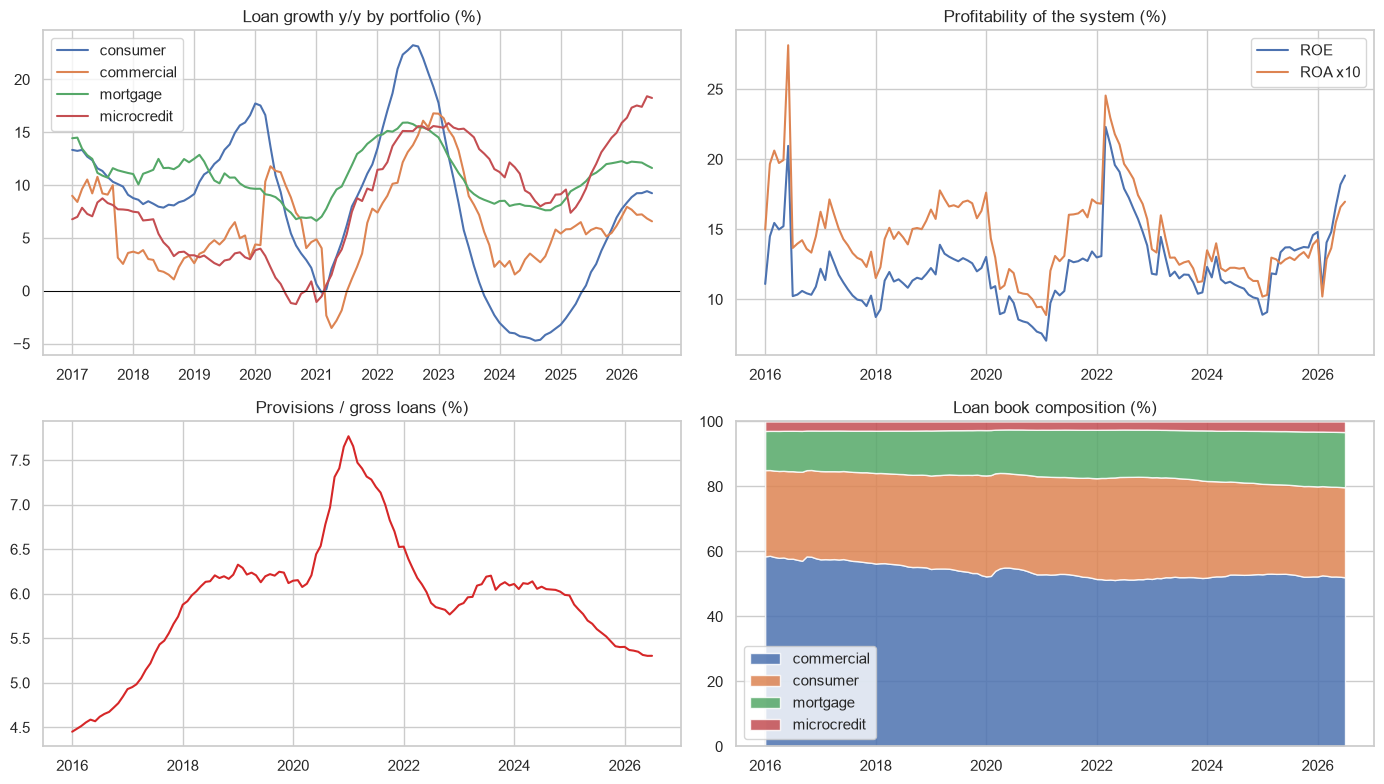

In [5]:
cols = ["assets", "gross_loans", "mortgage", "consumer", "commercial", "microcredit", "provisions", "equity", "net_income_ytd"]
sis = df.groupby("date")[cols].sum()
sis["month"] = sis.index.month
sis["roa"] = sis["net_income_ytd"] * 12 / sis["month"] / sis["assets"] * 100
sis["roe"] = sis["net_income_ytd"] * 12 / sis["month"] / sis["equity"] * 100
sis["coverage"] = sis["provisions"] / sis["gross_loans"] * 100
for c in ["consumer", "commercial", "mortgage", "microcredit"]:
    sis[c + "_yoy"] = sis[c].pct_change(12) * 100

fecha = sis.index.to_timestamp()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for c in ["consumer", "commercial", "mortgage", "microcredit"]:
    axes[0, 0].plot(fecha, sis[c + "_yoy"], label=c)
axes[0, 0].axhline(0, color="black", lw=0.7)
axes[0, 0].set_title("Loan growth y/y by portfolio (%)")
axes[0, 0].legend()
axes[0, 1].plot(fecha, sis["roe"], label="ROE")
axes[0, 1].plot(fecha, sis["roa"] * 10, label="ROA x10")
axes[0, 1].set_title("Profitability of the system (%)")
axes[0, 1].legend()
axes[1, 0].plot(fecha, sis["coverage"], color="tab:red")
axes[1, 0].set_title("Provisions / gross loans (%)")
mix = sis[["commercial", "consumer", "mortgage", "microcredit"]].div(sis["gross_loans"], axis=0) * 100
axes[1, 1].stackplot(fecha, mix.T.values, labels=mix.columns, alpha=0.85)
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Loan book composition (%)")
axes[1, 1].legend(loc="lower left")
plt.tight_layout()
plt.savefig("figures/system_trends.png", bbox_inches="tight")
plt.show()

In [6]:
dic = sis[sis.index.month == 12][["roa", "roe", "coverage"]].round(2)
dic.index = dic.index.year
print("Latest month:", sis.index[-1])
print("ROA:", round(sis["roa"].iloc[-1], 2), "| ROE:", round(sis["roe"].iloc[-1], 2), "| coverage:", round(sis["coverage"].iloc[-1], 2))
print("Consumer loans y/y, peak:", sis["consumer_yoy"].idxmax(), round(sis["consumer_yoy"].max(), 1))
print("Consumer loans y/y, lowest since 2022:", sis.loc["2022":, "consumer_yoy"].idxmin(), round(sis.loc["2022":, "consumer_yoy"].min(), 1))
print("Consumer loans y/y, latest:", round(sis["consumer_yoy"].iloc[-1], 1))
dic

Latest month: 2026-07
ROA: 1.7 | ROE: 18.84 | coverage: 5.3
Consumer loans y/y, peak: 2022-08 23.2
Consumer loans y/y, lowest since 2022: 2024-08 -4.7
Consumer loans y/y, latest: 9.2


cuenta,roa,roe,coverage
date,,,
2016,1.45,10.90,4.84
2017,1.34,10.27,5.74
2018,1.56,11.80,6.21
2019,1.63,12.24,6.12
2020,0.94,7.70,7.65
2021,1.71,13.42,6.52
2022,1.57,13.85,5.82
2023,1.13,10.50,6.09
2024,1.13,10.06,5.99


Consumer credit grew more than 20% a year in 2022 and then shrank in 2024, when high interest rates and defaults hit households. Profitability fell in 2023-2024 (ROE close to 10%) because banks had to provision more, and it recovered in 2025-2026.

## Part 6. Bank by bank in the latest month

In [7]:
ult = df[df["date"] == df["date"].max()].set_index("bank")
ult = ult[ult["assets"] > ult["assets"].sum() * 0.002]   # we drop very small or new entities
ult["market_share"] = ult["assets"] / ult["assets"].sum() * 100

ratios = ["market_share", "roa", "roe", "equity_to_assets", "loans_to_assets", "coverage",
          "liquid_to_assets", "consumer_share", "commercial_share", "mortgage_share"]
tabla = ult[ratios].sort_values("market_share", ascending=False).round(2)
tabla.to_csv("data/bank_ratios_latest.csv")
print("Top 5 banks, share of assets:", round(tabla["market_share"].head(5).sum(), 1), "%")
tabla.head(15)

Top 5 banks, share of assets: 71.5 %


cuenta,market_share,roa,roe,equity_to_assets,loans_to_assets,coverage,liquid_to_assets,consumer_share,commercial_share,mortgage_share
bank,,,,,,,,,,
Bancolombia,26.25,2.73,29.53,9.25,71.53,5.90,25.60,19.79,64.93,14.79
Banco Davivienda,14.43,1.52,16.19,9.38,75.30,5.36,22.43,20.94,47.41,31.65
Banco De Bogota,12.44,0.91,9.19,9.86,67.77,4.73,27.90,23.69,61.81,14.49
Bbva Colombia,10.76,0.80,13.21,6.05,66.85,4.47,29.88,33.87,47.39,18.74
Banco De Occidente,7.63,0.79,12.48,6.36,60.84,4.58,37.30,24.31,67.75,7.95
Banco Agrario De Colombia,3.84,1.60,19.70,8.11,56.83,8.34,42.57,11.71,35.68,2.96
Scotiabank Colpatria,3.57,0.45,5.67,7.85,66.15,6.16,30.44,46.39,31.22,22.40
Banco Gnb Sudameris,3.06,3.87,29.46,13.13,38.18,4.02,56.51,52.75,47.21,0.04
Banco Popular,2.86,0.18,2.31,7.65,68.86,4.70,26.83,68.88,28.07,3.06


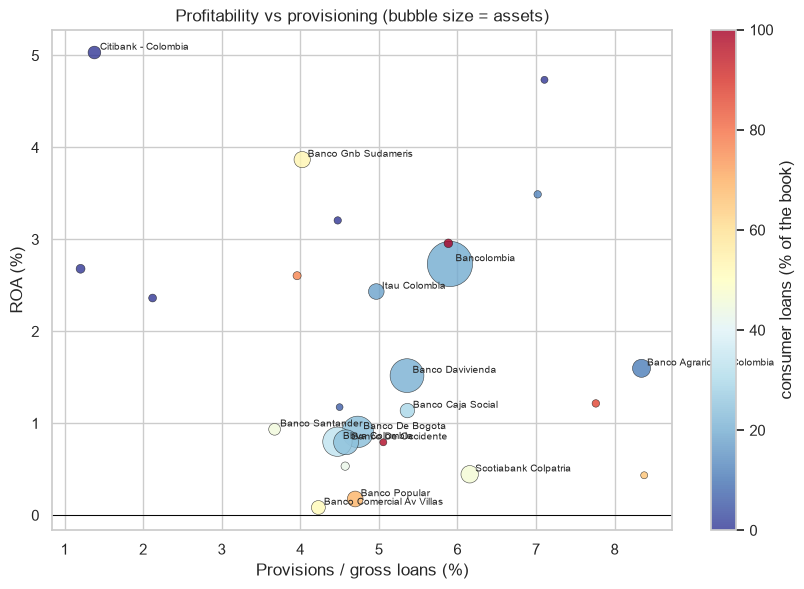

In [8]:
plt.figure(figsize=(10, 6.5))
sc = plt.scatter(ult["coverage"], ult["roa"], s=ult["market_share"] * 40 + 15, c=ult["consumer_share"],
                 cmap="RdYlBu_r", alpha=0.8, edgecolor="k", lw=0.4)
for b, r in ult.iterrows():
    if r["market_share"] > 1.2:
        plt.annotate(b, (r["coverage"], r["roa"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
plt.colorbar(sc, label="consumer loans (% of the book)")
plt.axhline(0, color="black", lw=0.7)
plt.title("Profitability vs provisioning (bubble size = assets)")
plt.xlabel("Provisions / gross loans (%)")
plt.ylabel("ROA (%)")
plt.savefig("figures/peer_map.png", bbox_inches="tight")
plt.show()

## Part 7. Clustering the banks by business model

We use K-means with the balance sheet structure and the risk ratios. Before that we cap extreme values (2% and 98%) and scale the variables, so the distances are not dominated by the variables with bigger numbers.

In [9]:
feats = ["equity_to_assets", "loans_to_assets", "coverage", "liquid_to_assets",
         "consumer_share", "commercial_share", "mortgage_share", "roa"]
x = ult[feats].clip(lower=ult[feats].quantile(0.02), upper=ult[feats].quantile(0.98), axis=1)
xs = StandardScaler().fit_transform(x)

# we choose k with the silhouette
siluetas = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=0).fit(xs)
    siluetas[k] = silhouette_score(xs, km.labels_)
    print("k =", k, "| silhouette:", round(siluetas[k], 3))

k = 2 | silhouette: 0.431
k = 3 | silhouette: 0.307
k = 4 | silhouette: 0.346


k = 5 | silhouette: 0.313
k = 6 | silhouette: 0.297


In [10]:
k = max(siluetas, key=siluetas.get)
km = KMeans(n_clusters=k, n_init=50, random_state=0).fit(xs)
ult["cluster"] = km.labels_

perfil = ult.groupby("cluster")[feats].median().round(1)
perfil["banks"] = ult.groupby("cluster").size()
perfil["market_share"] = ult.groupby("cluster")["market_share"].sum().round(1)
for c in sorted(ult["cluster"].unique()):
    print("Cluster", c, ":", ", ".join(ult[ult["cluster"] == c].index))
perfil

Cluster 0 : Banco De Bogota, Banco Popular, Itau Colombia, Bancolombia, Bbva Colombia, Banco De Occidente, Banco Caja Social, Banco Davivienda, Scotiabank Colpatria, Banco Agrario De Colombia, Banco Comercial Av Villas, Bancien, Bancamia, Banco W, Banco Coomeva, Banco Finandina, Banco Falabella, Banco Pichincha, Banco Santander, Banco Mundo Mujer, Mi Banco, Banco Serfinanza
Cluster 1 : Citibank - Colombia, Banco Gnb Sudameris, Banco J.P. Morgan Colombia, Banco Btg Pactual Colombia


cuenta,equity_to_assets,loans_to_assets,coverage,liquid_to_assets,consumer_share,commercial_share,mortgage_share,roa,banks,market_share
cluster,,,,,,,,,,
0,9.3,72.7,5.0,24.6,31.8,29.1,3.0,1.2,22,94.2
1,16.1,27.5,1.8,68.0,0.0,100.0,0.0,3.3,4,5.8


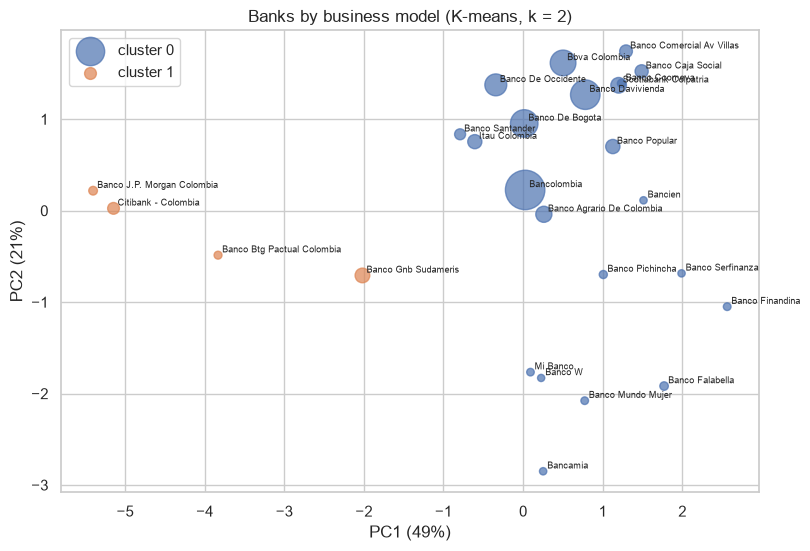

In [11]:
pca = PCA(n_components=2).fit(xs)
p = pca.transform(xs)
plt.figure(figsize=(9, 6))
for c in sorted(ult["cluster"].unique()):
    m = ult["cluster"].values == c
    plt.scatter(p[m, 0], p[m, 1], s=ult["market_share"].values[m] * 30 + 20, alpha=0.7, label="cluster " + str(c))
for b, (a, o) in zip(ult.index, p):
    plt.annotate(b, (a, o), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
plt.title(f"Banks by business model (K-means, k = {k})")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.legend()
plt.savefig("figures/bank_clusters.png", bbox_inches="tight")
plt.show()

## Conclusions

- The system is concentrated: the 5 biggest banks have around 70% of the assets.
- The silhouette is highest with 2 groups. The first one is the traditional retail and commercial banks (most of the system). The second one is wholesale or investment banks with few loans, a lot of liquid assets, more capital and higher ROA.
- Today some banks with a big consumer book have the lowest ROA of the system (Banco Popular, AV Villas, Scotiabank Colpatria), but it is not a rule: Banco Falabella and Banco Pichincha are mostly consumer lenders and have ROA above 2.5%. The consumer business is profitable when the pricing and the collection are good.